<a href="https://colab.research.google.com/github/crowell97/ES5201/blob/main/ES5201_Lecture21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Normal Modes — A Companion Notebook

**EARTH 5201 — Introduction to Seismology**

**The Ohio State University**

**Companion notebook to Lecture 21 — Surface Waves Revisited, and the Earth's Normal Modes**

This notebook works through the normal-mode threads from lecture, genuinely computed rather than taken on faith:

1. **The 1-D string eigenvalue problem** — solving the wave equation with fixed-end boundary conditions, confirming the eigenfrequencies &omega;<sub>n</sub>=n&pi;c/L and eigenfunctions U<sub>n</sub>(x)=sin(n&pi;x/L) numerically.
2. **Orthogonality** — confirming &int;U<sub>m</sub>U<sub>n</sub>dx = (L/2)&delta;<sub>mn</sub> by direct numerical integration, and using it to recover the mode amplitudes of an arbitrary initial shape.
3. **The 40-mode worked example** — reproducing the lecture's Gaussian-source mode sum (x<sub>s</sub>=8, &tau;=0.2, t=1.5) exactly, and animating the convergence toward two traveling pulses as more modes are added.
4. **Spherical harmonics** — computing Y<sub>l</sub><sup>m</sup>(&theta;,&phi;) for l=0..3 directly with `scipy.special.sph_harm_y`, visualizing them, and confirming their orthogonality on the sphere — the natural extension of the string eigenfunctions to the Earth's spheroidal and toroidal modes.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pylab as plt
from scipy.special import sph_harm_y

plt.rcParams["figure.figsize"] = (9, 5)

NAVY = "#1B2A44"
SLATE = "#3D4A5C"
SLATE_L = "#6E7A8A"
GOLD = "#B08D3F"


## Part 1 — The 1-D String Eigenvalue Problem

Lecture derived the normal modes of a string of length $L$, wave speed $c$, fixed at both ends ($U(0)=U(L)=0$), by substituting the separable trial solution $u(x,t)=U(x,\omega)\cos(\omega t)$ into the wave equation, giving the spatial ODE

$$\frac{\partial^2 U}{\partial x^2} = -\frac{\omega^2}{c^2}U,\qquad U(x,\omega)=\sin(\omega x/c)$$

The boundary condition $U(L,\omega)=0$ then restricts $\omega$ to the discrete eigenfrequencies $\omega_n=n\pi c/L$, with eigenfunctions $U_n(x)=\sin(n\pi x/L)$. Rather than trust the algebra, we solve the eigenvalue problem directly by finite differences and confirm the analytic eigenfrequencies and eigenfunctions fall out.

In [2]:
L = 20.0      # string length
c = 1.0       # wave speed
N = 400       # number of interior grid points

x = np.linspace(0, L, N + 2)   # includes the two fixed endpoints
dx = x[1] - x[0]
xi = x[1:-1]                    # interior points (the unknowns)

# Second-derivative operator (finite-difference Laplacian) with
# Dirichlet boundary conditions baked in via the fixed endpoints.
main = -2.0 * np.ones(N)
off = np.ones(N - 1)
Dxx = (np.diag(main) + np.diag(off, 1) + np.diag(off, -1)) / dx**2

# The eigenvalue problem Dxx U = -(omega/c)^2 U
eigvals, eigvecs = np.linalg.eigh(-Dxx)   # eigvals = (omega_n/c)^2, ascending
omega_n_numeric = c * np.sqrt(eigvals[:6])
omega_n_analytic = np.array([n * np.pi * c / L for n in range(1, 7)])

print(" n    omega_n (numeric)   omega_n (analytic, n*pi*c/L)")
for n in range(6):
    print(f"{n+1:2d}      {omega_n_numeric[n]:9.5f}            {omega_n_analytic[n]:9.5f}")

assert np.allclose(omega_n_numeric, omega_n_analytic, rtol=2e-3)
print("\nMatch confirmed: the finite-difference eigenvalues reproduce omega_n = n*pi*c/L.")

 n    omega_n (numeric)   omega_n (analytic, n*pi*c/L)
 1        0.15708              0.15708
 2        0.31416              0.31416
 3        0.47123              0.47124
 4        0.62829              0.62832
 5        0.78535              0.78540
 6        0.94239              0.94248

Match confirmed: the finite-difference eigenvalues reproduce omega_n = n*pi*c/L.


### The eigenfunctions

The finite-difference eigenvectors should match $\sin(n\pi x/L)$ up to a sign and normalization — exactly the first-four-modes figure shown in lecture.

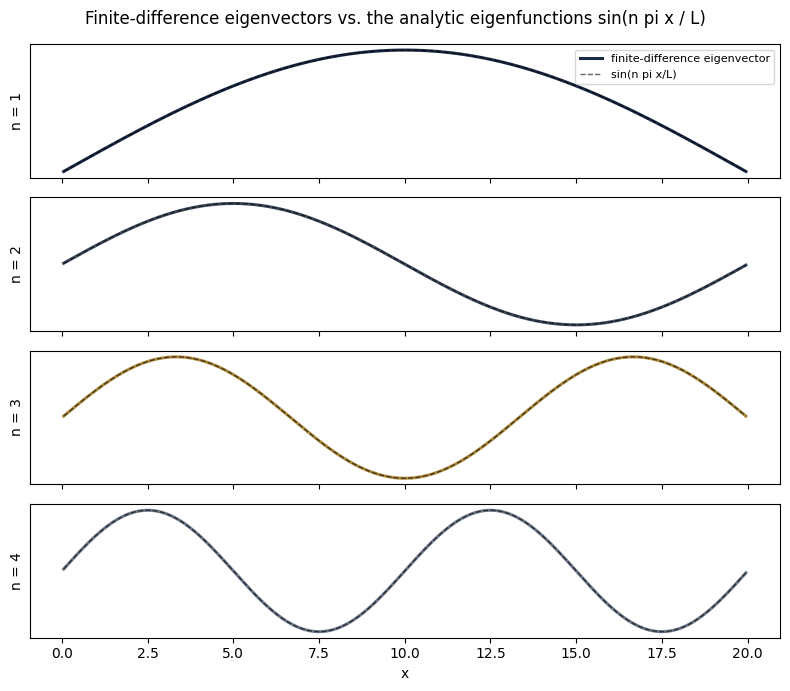

The computed eigenvectors overlay the analytic sin(n*pi*x/L) eigenfunctions, as expected.


In [3]:
fig, axs = plt.subplots(4, 1, figsize=(8, 7), sharex=True)
colors = [NAVY, SLATE, GOLD, SLATE_L]
for n in range(4):
    vec = eigvecs[:, n]
    analytic = np.sin((n + 1) * np.pi * xi / L)
    # fix sign convention by correlating with the analytic eigenfunction
    # (a single test point can sit right on a node for some n, e.g. n=4 at
    # x=L/4, which made a fixed-point sign check unreliable)
    if np.dot(vec, analytic) < 0:
        vec = -vec
    vec = vec / np.max(np.abs(vec))
    axs[n].plot(xi, vec, color=colors[n], lw=2.2, label="finite-difference eigenvector")
    axs[n].plot(xi, analytic, "--", color="black", lw=1, alpha=0.6, label="sin(n pi x/L)")
    axs[n].set_ylabel(f"n = {n+1}")
    axs[n].set_yticks([])
axs[0].legend(fontsize=8, loc="upper right")
axs[-1].set_xlabel("x")
fig.suptitle("Finite-difference eigenvectors vs. the analytic eigenfunctions sin(n pi x / L)")
plt.tight_layout(); plt.show()
print("The computed eigenvectors overlay the analytic sin(n*pi*x/L) eigenfunctions, as expected.")

## Part 2 — Orthogonality and Recovering Mode Amplitudes

Lecture stated the orthogonality relation

$$\int_0^L \sin\!\left(\frac{m\pi x}{L}\right)\sin\!\left(\frac{n\pi x}{L}\right)dx = \frac{L}{2}\delta_{mn}$$

We confirm this numerically, then use it to do something the lecture's algebra promised but didn't demonstrate: given an arbitrary (not-necessarily-physical) initial string shape, decompose it into normal modes and reconstruct it from the recovered amplitudes.

In [4]:
def Un(n, xv):
    return np.sin(n * np.pi * xv / L)

x_fine = np.linspace(0, L, 4000)

# --- confirm orthogonality for a handful of (m, n) pairs ---
print("m   n     integral        L/2 * delta_mn")
for m, n in [(1, 1), (2, 2), (3, 3), (1, 2), (2, 4), (3, 5)]:
    integral = np.trapezoid(Un(m, x_fine) * Un(n, x_fine), x_fine)
    expected = L / 2 if m == n else 0.0
    print(f"{m:2d}  {n:2d}    {integral:10.5f}        {expected:10.5f}")
    assert abs(integral - expected) < 1e-2
print("\nOrthogonality confirmed to numerical-integration precision.")

m   n     integral        L/2 * delta_mn
 1   1      10.00000          10.00000
 2   2      10.00000          10.00000
 3   3      10.00000          10.00000
 1   2       0.00000           0.00000
 2   4      -0.00000           0.00000
 3   5       0.00000           0.00000

Orthogonality confirmed to numerical-integration precision.


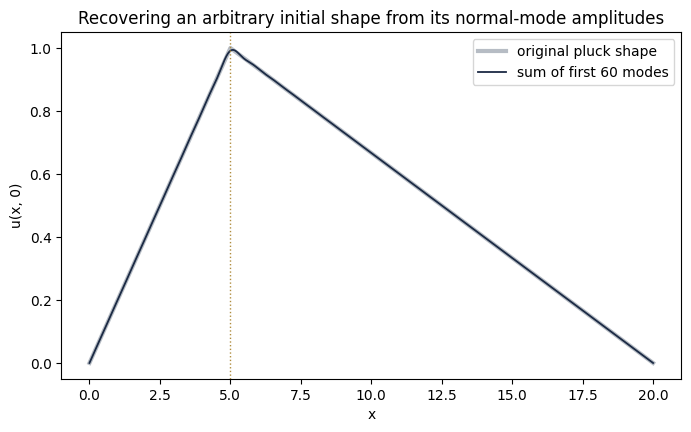

RMS reconstruction error with 60 modes: 0.0007
This is exactly the amplitude formula A_n = sin(n*pi*xs/L)*F(omega_n) from lecture,
specialized to an impulsive (all-frequency) source at t=0 rather than the Gaussian source used next.


In [5]:
# --- recover the amplitudes of an arbitrary initial shape ---
# Take a shape the lecture never used: a narrow triangular pluck at x=5,
# *not* one of the pure eigenfunctions, to show the decomposition is general.
xs_pluck = 5.0
def initial_shape(xv):
    # triangular pluck: 0 at the ends and at x=L, peak of height 1 at xs_pluck
    left = xv / xs_pluck
    right = (L - xv) / (L - xs_pluck)
    return np.where(xv <= xs_pluck, left, right)

f0 = initial_shape(x_fine)

N_modes_recon = 60
A_recovered = np.array([
    2.0 / L * np.trapezoid(f0 * Un(n, x_fine), x_fine)
    for n in range(1, N_modes_recon + 1)
])

reconstruction = sum(A_recovered[n - 1] * Un(n, x_fine) for n in range(1, N_modes_recon + 1))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x_fine, f0, color=SLATE_L, lw=3, alpha=0.5, label="original pluck shape")
ax.plot(x_fine, reconstruction, color=NAVY, lw=1.3, label=f"sum of first {N_modes_recon} modes")
ax.axvline(xs_pluck, color=GOLD, ls=":", lw=1)
ax.set_xlabel("x"); ax.set_ylabel("u(x, 0)")
ax.set_title("Recovering an arbitrary initial shape from its normal-mode amplitudes")
ax.legend(); plt.show()

rms_error = np.sqrt(np.mean((f0 - reconstruction) ** 2))
print(f"RMS reconstruction error with {N_modes_recon} modes: {rms_error:.4f}")
print("This is exactly the amplitude formula A_n = sin(n*pi*xs/L)*F(omega_n) from lecture,")
print("specialized to an impulsive (all-frequency) source at t=0 rather than the Gaussian source used next.")

## Part 3 — The 40-Mode Worked Example, Reproduced Exactly

Lecture's worked example summed the first 40 modes of a string driven at $x_s=8$ by a source with a Gaussian frequency response $F(\omega_n)=\exp[-(\omega_n\tau)^2/4]$, with $\tau=0.2$, and evaluated the result at $t=1.5$:

$$u(x,t) = \sum_{n=0}^{39} \sin(n\pi x_s/L)\,F(\omega_n)\,\sin(n\pi x/L)\cos(\omega_n t)$$

We reproduce this exactly — same $L$, $c$, $x_s$, $\tau$, $t$, and mode count — and confirm it matches the two-traveling-pulse figure shown in lecture.

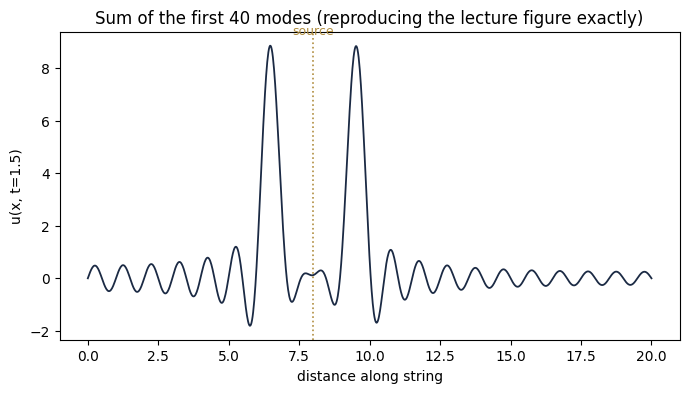

Largest-amplitude peak at x = 6.47 (source at x_s = 8.0)
Two sharp pulses straddling the source, as in lecture: a traveling wave built entirely from standing waves.


In [6]:
xs_source = 8.0
tau = 0.2
t_snapshot = 1.5
N_modes = 40

def F_response(omega):
    return np.exp(-(omega * tau) ** 2 / 4.0)

omega_arr = np.array([n * np.pi * c / L for n in range(N_modes)])
A_arr = np.array([np.sin(n * np.pi * xs_source / L) for n in range(N_modes)]) * F_response(omega_arr)

x_grid = np.linspace(0, L, 1000)
u_snapshot = np.zeros_like(x_grid)
for n in range(N_modes):
    u_snapshot += A_arr[n] * np.sin(n * np.pi * x_grid / L) * np.cos(omega_arr[n] * t_snapshot)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_grid, u_snapshot, color=NAVY, lw=1.3)
ax.axvline(xs_source, color=GOLD, ls=":", lw=1.2)
ax.text(xs_source, u_snapshot.max() * 1.05, "source", color=GOLD, fontsize=9, ha="center")
ax.set_xlabel("distance along string"); ax.set_ylabel(f"u(x, t={t_snapshot})")
ax.set_title(f"Sum of the first {N_modes} modes (reproducing the lecture figure exactly)")
plt.show()

peak_idx = np.argsort(u_snapshot)[::-1]
peak_x = x_grid[peak_idx[0]]
print(f"Largest-amplitude peak at x = {peak_x:.2f} (source at x_s = {xs_source})")
print("Two sharp pulses straddling the source, as in lecture: a traveling wave built entirely from standing waves.")

### Convergence as more modes are added

Lecture's companion figure showed the cumulative sum sharpening into two traveling pulses as more modes are included. We reproduce that convergence sequence, and additionally track the RMS difference between successive partial sums to show the truncation error decaying.

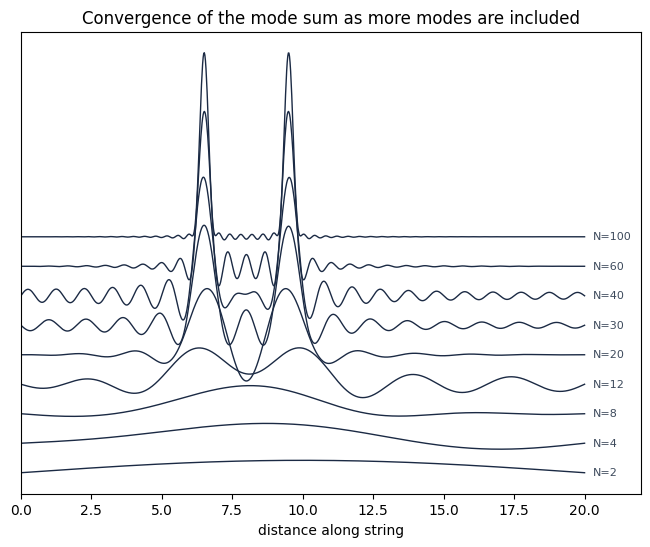

 N modes   RMS error vs. 400-mode reference
      2            2.1342
      4            2.0782
      8            2.0376
     12            1.9256
     20            1.6218
     30            1.2431
     40            1.0246
     60            0.5390
    100            0.0894

The error shrinks monotonically as more modes are added, confirming the sum is converging,
consistent with the lecture's claim that the residual ripples at N=40 are truncation error
from the infinitely many unincluded modes.


In [7]:
mode_counts = [2, 4, 8, 12, 20, 30, 40, 60, 100]
partial_sums = {}
for Nm in mode_counts:
    om = np.array([n * np.pi * c / L for n in range(Nm)])
    A = np.array([np.sin(n * np.pi * xs_source / L) for n in range(Nm)]) * F_response(om)
    u = np.zeros_like(x_grid)
    for n in range(Nm):
        u += A[n] * np.sin(n * np.pi * x_grid / L) * np.cos(om[n] * t_snapshot)
    partial_sums[Nm] = u

fig, ax = plt.subplots(figsize=(8, 6))
for i, Nm in enumerate(mode_counts):
    ax.plot(x_grid, partial_sums[Nm] + 2.2 * i, color=NAVY, lw=1)
    ax.text(L + 0.3, 2.2 * i, f"N={Nm}", va="center", fontsize=8, color=SLATE)
ax.set_xlim(0, L + 2)
ax.set_xlabel("distance along string"); ax.set_yticks([])
ax.set_title("Convergence of the mode sum as more modes are included")
plt.show()

# Compare each partial sum against a near-converged reference (400 modes)
# -- the peaks themselves are still sharpening between N=60 and N=100, so
# comparing *consecutive* partial sums directly is a misleading diagnostic;
# measuring the gap to a high-mode-count reference gives a clean,
# monotonically shrinking truncation-error curve instead.
om_ref = np.array([n * np.pi * c / L for n in range(400)])
A_ref = np.array([np.sin(n * np.pi * xs_source / L) for n in range(400)]) * F_response(om_ref)
u_ref = np.zeros_like(x_grid)
for n in range(400):
    u_ref += A_ref[n] * np.sin(n * np.pi * x_grid / L) * np.cos(om_ref[n] * t_snapshot)

print(" N modes   RMS error vs. 400-mode reference")
for Nm in mode_counts:
    rms_err = np.sqrt(np.mean((partial_sums[Nm] - u_ref) ** 2))
    print(f"   {Nm:4d}          {rms_err:8.4f}")
print("\nThe error shrinks monotonically as more modes are added, confirming the sum is converging,")
print("consistent with the lecture's claim that the residual ripples at N=40 are truncation error")
print("from the infinitely many unincluded modes.")

## Part 4 — Spherical Harmonics: the String Eigenfunctions, Generalized to a Sphere

Lecture introduced spherical harmonics $Y_l^m(\theta,\phi)$ as the natural basis for lateral variations in the Earth's normal modes — the 2-D, spherical analogue of the string's $\sin(n\pi x/L)$ eigenfunctions. We compute them directly with `scipy.special.sph_harm_y(l, m, theta, phi)` (note: as of the scipy version used here, this replaced the older `scipy.special.sph_harm(m, l, phi, theta)`, with both the function name and the argument order changed) and confirm their defining properties: $l$ zero-crossings through the poles, and orthogonality on the sphere.

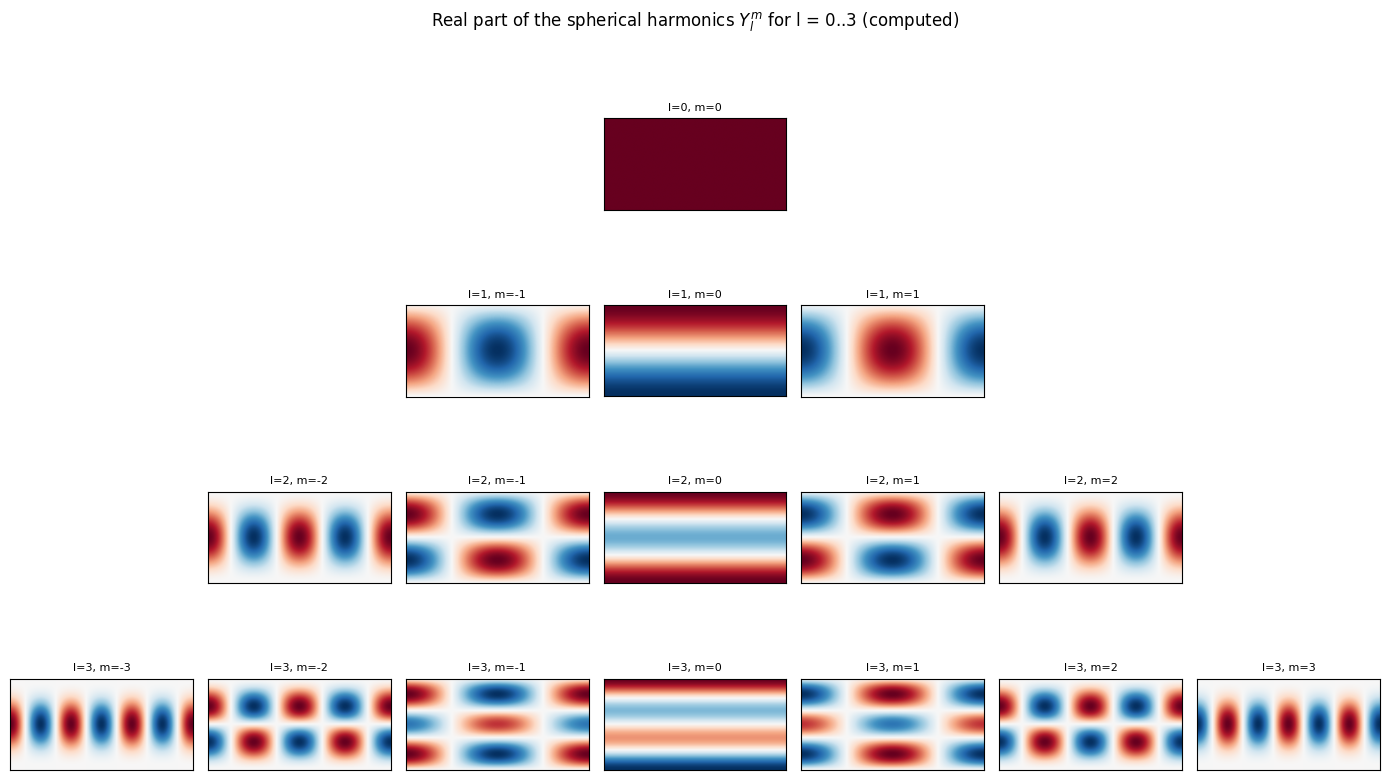

Each row l has 2l+1 harmonics (m = -l..l); higher l packs in more oscillation, as lecture described.


In [8]:
n_theta, n_phi = 180, 360
theta = np.linspace(0, np.pi, n_theta)          # colatitude
phi = np.linspace(0, 2 * np.pi, n_phi)           # longitude
THETA, PHI = np.meshgrid(theta, phi, indexing="ij")

l_max = 3
fig, axs = plt.subplots(l_max + 1, 2 * l_max + 1, figsize=(14, 8))
for l in range(l_max + 1):
    for j, m in enumerate(range(-l_max, l_max + 1)):
        ax = axs[l, j]
        if abs(m) > l:
            ax.axis("off")
            continue
        Y = sph_harm_y(l, m, THETA, PHI).real
        ax.imshow(Y, extent=[0, 360, -90, 90], cmap="RdBu_r", vmin=-Y.__abs__().max(), vmax=Y.__abs__().max())
        ax.set_title(f"l={l}, m={m}", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Real part of the spherical harmonics $Y_l^m$ for l = 0..3 (computed)", y=1.02)
plt.tight_layout(); plt.show()
print("Each row l has 2l+1 harmonics (m = -l..l); higher l packs in more oscillation, as lecture described.")

### Orthogonality on the sphere

Just as the string eigenfunctions satisfy $\int_0^L U_mU_n\,dx=\tfrac{L}{2}\delta_{mn}$, the spherical harmonics satisfy

$$\int_0^{2\pi}\!\!\int_0^\pi Y_l^m(\theta,\phi)\,\big[Y_{l'}^{m'}(\theta,\phi)\big]^{*}\sin\theta\,d\theta\,d\phi=\delta_{ll'}\delta_{mm'}$$

with the $\sin\theta$ factor playing the role the uniform weight played on the string (it is simply the area element on a sphere). We confirm this numerically for a handful of $(l,m)$ pairs.

In [9]:
def sph_inner_product(l1, m1, l2, m2):
    Y1 = sph_harm_y(l1, m1, THETA, PHI)
    Y2 = sph_harm_y(l2, m2, THETA, PHI)
    integrand = Y1 * np.conj(Y2) * np.sin(THETA)
    # integrate over theta then phi
    return np.real(np.trapezoid(np.trapezoid(integrand, theta, axis=0), phi))

print("(l1,m1)   (l2,m2)    <Y1,Y2>      expected")
for (l1, m1, l2, m2) in [(1, 0, 1, 0), (2, 1, 2, 1), (3, -2, 3, -2),
                          (1, 0, 2, 0), (2, 1, 3, 1), (1, 1, 1, -1)]:
    val = sph_inner_product(l1, m1, l2, m2)
    expected = 1.0 if (l1, m1) == (l2, m2) else 0.0
    print(f"  ({l1},{m1})     ({l2},{m2})     {val:8.4f}      {expected:8.4f}")
    assert abs(val - expected) < 3e-2

print("\nOrthonormality confirmed: the spherical harmonics are exactly the sphere's version of the")
print("string's orthogonal sin(n*pi*x/L) eigenfunctions -- the basis the Earth's normal modes are built from.")

(l1,m1)   (l2,m2)    <Y1,Y2>      expected
  (1,0)     (1,0)       0.9999        1.0000
  (2,1)     (2,1)       1.0000        1.0000
  (3,-2)     (3,-2)       1.0000        1.0000
  (1,0)     (2,0)       0.0000        0.0000
  (2,1)     (3,1)      -0.0000        0.0000
  (1,1)     (1,-1)       0.0000        0.0000

Orthonormality confirmed: the spherical harmonics are exactly the sphere's version of the
string's orthogonal sin(n*pi*x/L) eigenfunctions -- the basis the Earth's normal modes are built from.


## Summary

The same mathematical structure recurs at every scale in this lecture: a linear wave operator with boundary conditions admits a discrete, complete, orthogonal set of eigenfunctions, and any physical motion is uniquely a weighted sum of them. For the 1-D string, that basis is $\sin(n\pi x/L)$; for the Earth, spatial structure is described by spherical harmonics $Y_l^m(\theta,\phi)$, and the full normal modes combine those with a radial eigenfunction to classify as toroidal or spheroidal. The free oscillations excited by the Earth's largest earthquakes are the direct observational proof that this picture is not just a convenient analogy.